# Which Customers Will Leave, and How Much Can We Save?
### Customer churn analysis for a telecom company

**Tools:** Python (pandas, scikit-learn), Matplotlib | **Data:** IBM Telco Customer Churn sample (7,043 customers)

## Summary

**Main finding:** churn is concentrated, so it can be targeted. New customers on month-to-month contracts with fiber internet leave at **70%**, while long-term customers on two-year contracts leave at **3%**. A simple model finds the risky customers well enough that a targeted retention offer would earn about **$243,000** a year, more than three times as much as giving the offer to everyone.

| Question | Answer |
|---|---|
| **How big is the problem?** | 1,869 of 7,043 customers (**26.5%**) left in one month, taking **$139,000 a month** (30.5% of revenue) with them, or about **$1.67 million a year** |
| **Who leaves?** | Month-to-month contracts (43% leave, against 3% on two-year contracts), new customers (53% in their first 6 months), fiber internet (42%) and electronic check payments (45%) |
| **Riskiest group** | Month-to-month, 12 months or less, fiber internet: **70% leave** (916 customers) |
| **Can we predict it?** | Yes. Calling the 20% of customers with the highest risk scores reaches **50% of all leavers**, against 20% for random calls |
| **What should the company do?** | Give a retention offer to the riskiest **41%** of customers: about **$243,000 net profit**, against $71,000 for offering it to everyone |

**Recommendation:** focus retention money on new month-to-month customers, especially those with fiber internet, and move customers onto longer contracts and automatic payments.

**Main limitation:** this is IBM's fictional sample data, and the offer's cost and success rate are assumptions that a real company should test first.

## 1. The business problem

A telecom company is losing customers. Every customer who leaves ("churns") takes their monthly bill with them, and winning a new customer usually costs much more than keeping an existing one.

The company has a budget for **retention offers**, such as a discount, to persuade customers to stay. But it can't afford to give an offer to everyone, so it needs to know **who to target**.

**Questions:**
1. How many customers leave, and how much money does that cost?
2. Which kinds of customers leave most often?
3. What does the riskiest customer look like?
4. Can a model predict who will leave?
5. How many customers should get an offer, and how much money would that save?

**About the data:** each row is one customer: their services, contract, payment method, monthly bill and how long they've been a customer (*tenure*, in months). The `Churn` column says whether they left in the last month.

## 2. Setup

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

DATA_FILE = 'data/WA_Fn-UseC_-Telco-Customer-Churn.csv'
RED, BLUE, GREY = '#C53030', '#2B6CB0', '#A0AEC0'
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.titlesize': 12})
pd.set_option('display.float_format', lambda v: f'{v:,.1f}')
for folder in ['figures', 'outputs']:
    os.makedirs(folder, exist_ok=True)

## 3. Load and check the data

`TotalCharges` is stored as text, and it is blank for a few customers. The check below shows they are all brand-new customers (0 months of tenure) who haven't been billed yet, so their total is set to 0.

In [2]:
df = pd.read_csv(DATA_FILE)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
blank = df['TotalCharges'].isna()
print(f"Blank TotalCharges: {blank.sum()} customers, tenure of these customers: {sorted(df.loc[blank, 'tenure'].unique())}")
df['TotalCharges'] = df['TotalCharges'].fillna(0)

df['left'] = (df['Churn'] == 'Yes').astype(int)
df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'})
df['tenure_group'] = pd.cut(df['tenure'], [-1, 6, 12, 24, 48, 72],
                            labels=['0-6 months', '7-12 months', '1-2 years', '2-4 years', '4-6 years'])

checks = pd.DataFrame({
    'Check': ['Customers', 'Columns', 'Duplicate customer IDs', 'Missing values (after fix)', 'Customers who left'],
    'Result': [f'{len(df):,}', f'{df.shape[1] - 2}', f"{df['customerID'].duplicated().sum()}",
               f'{df.isna().sum().sum()}', f"{df['left'].sum():,} ({df['left'].mean():.1%})"]})
checks

Blank TotalCharges: 11 customers, tenure of these customers: [np.int64(0)]


,Check,Result
0,Customers,"7,043"
1,Columns,21
2,Duplicate customer IDs,0
3,Missing values (after fix),0
4,Customers who left,"1,869 (26.5%)"


## 4. Q1: How many customers leave, and what does it cost?

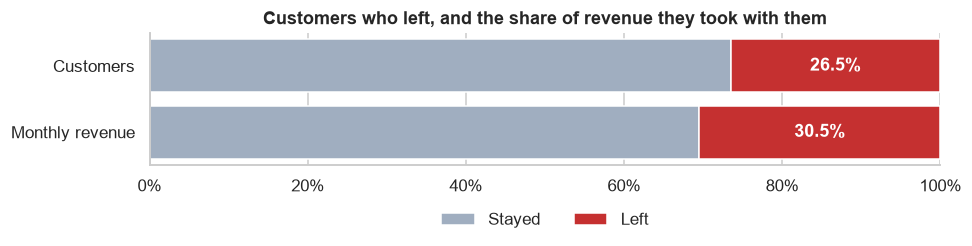

,Measure,Value
0,Customers,"7,043"
1,Customers who left,"1,869 (26.5%)"
2,Monthly revenue (all customers),"$456,117"
3,Monthly revenue lost,"$139,131 (30.5%)"
4,Revenue lost over a year,"$1,669,570"


In [3]:
monthly_revenue = df['MonthlyCharges'].sum()
lost_revenue = df.loc[df['left'] == 1, 'MonthlyCharges'].sum()

q1 = pd.DataFrame({
    'Measure': ['Customers', 'Customers who left', 'Monthly revenue (all customers)', 'Monthly revenue lost',
                'Revenue lost over a year'],
    'Value': [f'{len(df):,}', f"{df['left'].sum():,} ({df['left'].mean():.1%})", f'${monthly_revenue:,.0f}',
              f'${lost_revenue:,.0f} ({lost_revenue / monthly_revenue:.1%})', f'${12 * lost_revenue:,.0f}']})

fig, ax = plt.subplots(figsize=(9, 2.6))
shares = pd.DataFrame({'Stayed': [1 - df['left'].mean(), 1 - lost_revenue / monthly_revenue],
                       'Left': [df['left'].mean(), lost_revenue / monthly_revenue]},
                      index=['Customers', 'Monthly revenue']) * 100
shares = shares.iloc[::-1]   # draw 'Customers' on top
ax.barh(shares.index, shares['Stayed'], color=GREY, label='Stayed')
ax.barh(shares.index, shares['Left'], left=shares['Stayed'], color=RED, label='Left')
for i, (stay, left) in enumerate(zip(shares['Stayed'], shares['Left'])):
    ax.text(stay + left / 2, i, f'{left:.1f}%', ha='center', va='center', color='white', fontweight='bold')
ax.set_xlim(0, 100); ax.grid(axis='y', visible=False)
ax.xaxis.set_major_formatter(lambda v, _: f'{v:.0f}%')
ax.set_title('Customers who left, and the share of revenue they took with them')
ax.legend(frameon=False, ncol=2, bbox_to_anchor=(0.5, -0.25), loc='upper center')
plt.tight_layout(); plt.savefig('figures/01_churn_cost.png', bbox_inches='tight'); plt.show()
q1

**Insight:** about **1 in 4 customers (26.5%) left** in a single month. They took **30.5% of monthly revenue** with them, more than their share of customers, because leavers pay more on average: about **$74 a month**, against $61 for customers who stayed. Over a year, that's about **$1.67 million** in lost revenue, so even a small improvement is worth a lot.

## 5. Q2: Which kinds of customers leave most often?

Each bar is the **% of customers in that group who left**. The dashed line is the average for all customers. Red bars are groups that leave more often than average.

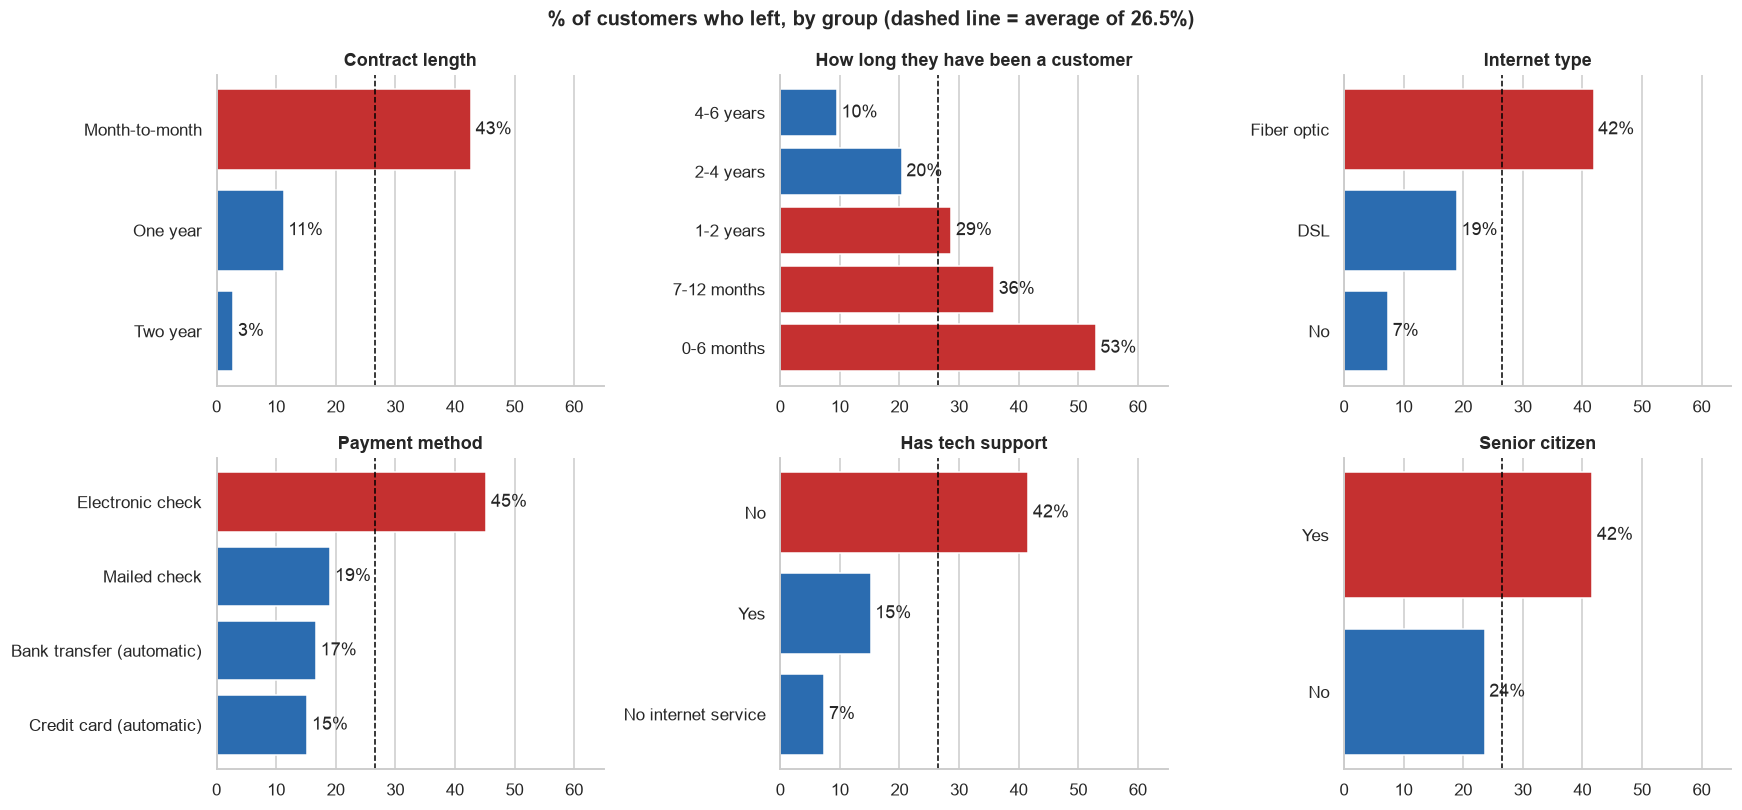

,group,customers,pct_left
3,tenure_group = 0-6 months,"1,481.0",52.9
13,PaymentMethod = Electronic check,"2,365.0",45.3
0,Contract = Month-to-month,"3,875.0",42.7
9,InternetService = Fiber optic,"3,096.0",41.9
18,OnlineSecurity = No,"3,498.0",41.8
22,SeniorCitizen = Yes,"1,142.0",41.7
15,TechSupport = No,"3,473.0",41.6
4,tenure_group = 7-12 months,705.0,35.9


In [4]:
average = df['left'].mean() * 100

def churn_by(column):
    out = df.groupby(column, observed=True)['left'].agg(['mean', 'size'])
    out['mean'] *= 100
    return out.rename(columns={'mean': 'pct_left', 'size': 'customers'})

FACTORS = [('Contract', 'Contract length'), ('tenure_group', 'How long they have been a customer'),
           ('InternetService', 'Internet type'), ('PaymentMethod', 'Payment method'),
           ('TechSupport', 'Has tech support'), ('SeniorCitizen', 'Senior citizen')]

fig, axes = plt.subplots(2, 3, figsize=(16, 7.5))
for ax, (column, title) in zip(axes.flat, FACTORS):
    t = churn_by(column)
    if column != 'tenure_group':
        t = t.sort_values('pct_left')
    ax.barh(t.index.astype(str), t['pct_left'], color=[RED if v > average else BLUE for v in t['pct_left']])
    ax.bar_label(ax.containers[0], fmt='%.0f%%', padding=3)
    ax.axvline(average, color='black', ls='--', lw=1)
    ax.set_xlim(0, 65); ax.set_title(title); ax.grid(axis='y', visible=False)
fig.suptitle(f'% of customers who left, by group (dashed line = average of {average:.1f}%)', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.savefig('figures/02_who_leaves.png', bbox_inches='tight'); plt.show()

# All groups with at least 300 customers, ranked by how often they leave
groups = []
for column in ['Contract', 'tenure_group', 'InternetService', 'PaymentMethod', 'TechSupport', 'OnlineSecurity',
               'SeniorCitizen', 'PaperlessBilling', 'Partner', 'Dependents', 'gender', 'StreamingTV']:
    for value, row in churn_by(column).iterrows():
        groups.append({'group': f'{column} = {value}', 'customers': row['customers'], 'pct_left': row['pct_left']})
groups = pd.DataFrame(groups)
groups = groups[groups['customers'] >= 300].sort_values('pct_left', ascending=False)
groups.head(8)

**Insight:** the clearest pattern is **commitment**. Customers who can leave at any time do leave:
- **Contract:** 43% of month-to-month customers left, against 11% on one-year and only **3% on two-year** contracts.
- **Time as a customer:** **53% of customers in their first 6 months** left, falling to 10% for customers of 4 to 6 years. The first year is the danger zone.
- **Internet type:** fiber optic customers leave more than twice as often as DSL customers (42% against 19%). This may point to a price or quality problem with the fiber service.
- **Payment:** 45% of customers paying by electronic check left, against 15–17% for automatic payments.
- **Support:** customers without tech support leave almost 3 times as often (42% against 15%).
- **Age:** senior citizens leave more often (42% against 24%).

## 6. Q3: What does the riskiest customer look like?

Adding the risk factors one at a time shows how quickly the chance of leaving climbs.

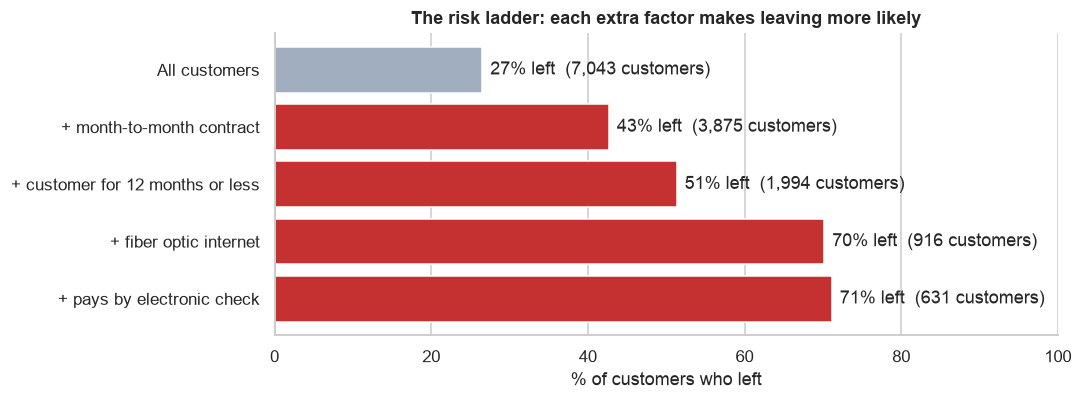

For comparison, customers on a two-year contract for over 2 years: 3.1% left (1,537 customers)


,step,customers,pct_left
0,All customers,7043,26.5
1,+ month-to-month contract,3875,42.7
2,+ customer for 12 months or less,1994,51.4
3,+ fiber optic internet,916,70.2
4,+ pays by electronic check,631,71.2


In [5]:
steps = [
    ('All customers', pd.Series(True, index=df.index)),
    ('+ month-to-month contract', df['Contract'] == 'Month-to-month'),
    ('+ customer for 12 months or less', df['tenure'] <= 12),
    ('+ fiber optic internet', df['InternetService'] == 'Fiber optic'),
    ('+ pays by electronic check', df['PaymentMethod'] == 'Electronic check'),
]
mask = pd.Series(True, index=df.index)
ladder = []
for label, condition in steps:
    mask = mask & condition
    ladder.append({'step': label, 'customers': int(mask.sum()), 'pct_left': 100 * df.loc[mask, 'left'].mean()})
ladder = pd.DataFrame(ladder)
safest = df[(df['Contract'] == 'Two year') & (df['tenure'] > 24)]

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh(ladder['step'][::-1], ladder['pct_left'][::-1], color=[RED if v > average else GREY for v in ladder['pct_left'][::-1]])
for i, r in enumerate(ladder[::-1].itertuples()):
    ax.text(r.pct_left + 1, i, f'{r.pct_left:.0f}% left  ({r.customers:,} customers)', va='center')
ax.set_xlim(0, 100); ax.set_xlabel('% of customers who left'); ax.grid(axis='y', visible=False)
ax.set_title('The risk ladder: each extra factor makes leaving more likely')
plt.tight_layout(); plt.savefig('figures/03_risk_ladder.png', bbox_inches='tight'); plt.show()
print(f"For comparison, customers on a two-year contract for over 2 years: {safest['left'].mean():.1%} left ({len(safest):,} customers)")
ladder

**Insight:** combining the factors makes the risk very clear. **New, month-to-month customers with fiber internet leave at 70%**, almost 3 times the average. This group is 916 customers, about 13% of the base. Adding electronic check payments barely changes the rate (71%), because most of these customers already pay that way. At the other end, customers on a two-year contract for more than 2 years almost never leave (**3%**).

## 7. Q4: Can a model predict who will leave?

I train a **logistic regression**, a simple model that gives each customer a **risk score** (the chance they'll leave) and shows which factors push the score up or down. It learns from 75% of customers, and I test it on the other 25%, which it has never seen.

**How I judge it, in plain words:** if the company can only call a limited number of customers, does the model help it find the ones who are really about to leave? I compare three ways of choosing who to call:
- **Model:** call the customers with the highest risk scores.
- **Simple rule:** call month-to-month customers first, newest customers first. No model needed.
- **Random:** call customers at random. This is the result with no analysis at all.

Test customers: 1,761, of whom 467 left
AUC (0.5 = guessing, 1.0 = perfect): model 0.84, simple rule 0.79


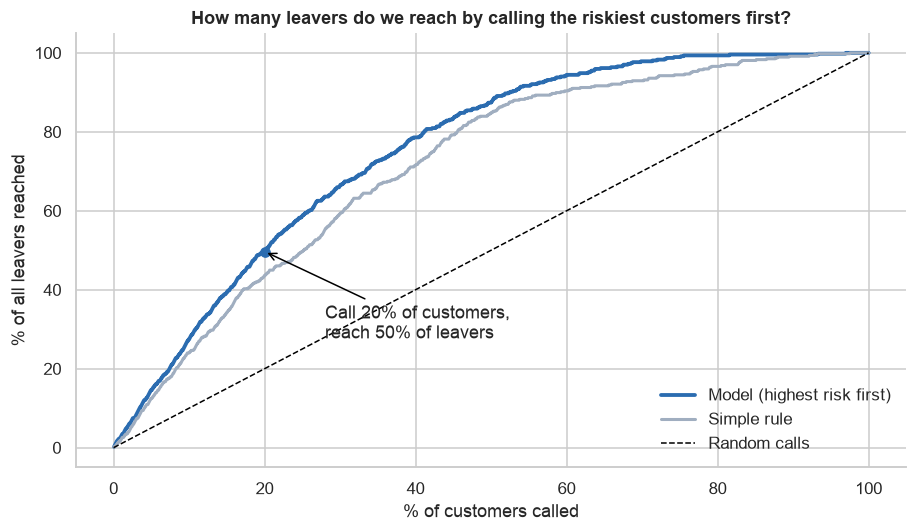

,% of leavers reached,% of called customers who were really leaving
Way of choosing who to call (20% of customers),,
Model,49.7,65.9
Simple rule,43.5,57.4
Random,20.0,26.5


In [6]:
# TotalCharges is left out: it is roughly tenure x monthly bill, so it repeats information the model already has,
# and that overlap makes the model's factors confusing to read
FEATURES = [c for c in df.columns if c not in ('customerID', 'Churn', 'left', 'tenure_group', 'TotalCharges')]
numeric = ['tenure', 'MonthlyCharges']
categorical = [c for c in FEATURES if c not in numeric]

train, test = train_test_split(df, test_size=0.25, stratify=df['left'], random_state=42)
model = make_pipeline(
    ColumnTransformer([('num', StandardScaler(), numeric),
                       ('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore'), categorical)]),
    LogisticRegression(max_iter=2000))
model.fit(train[FEATURES], train['left'])

test = test.copy()
test['risk'] = model.predict_proba(test[FEATURES])[:, 1]
test['rule_score'] = (test['Contract'] == 'Month-to-month') * 100 - test['tenure']   # month-to-month first, newest first
print(f"Test customers: {len(test):,}, of whom {test['left'].sum()} left")
print(f"AUC (0.5 = guessing, 1.0 = perfect): model {roc_auc_score(test['left'], test['risk']):.2f}, "
      f"simple rule {roc_auc_score(test['left'], test['rule_score']):.2f}")

def found_by_calling(score):
    # Call customers from highest to lowest score: what share of all leavers have we reached after each call?
    order = test.sort_values(score, ascending=False)
    return order['left'].cumsum().values / test['left'].sum() * 100

pct_called = np.arange(1, len(test) + 1) / len(test) * 100
found_model, found_rule = found_by_calling('risk'), found_by_calling('rule_score')

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.plot(pct_called, found_model, color=BLUE, lw=2.5, label='Model (highest risk first)')
ax.plot(pct_called, found_rule, color=GREY, lw=2, label='Simple rule')
ax.plot([0, 100], [0, 100], color='black', ls='--', lw=1, label='Random calls')
k = int(len(test) * 0.2) - 1
ax.scatter([20], [found_model[k]], color=BLUE, zorder=3)
ax.annotate(f'Call 20% of customers,\nreach {found_model[k]:.0f}% of leavers', (20, found_model[k]), xytext=(28, found_model[k] - 22),
            arrowprops=dict(arrowstyle='->', color='black'))
ax.set_xlabel('% of customers called'); ax.set_ylabel('% of all leavers reached')
ax.set_title('How many leavers do we reach by calling the riskiest customers first?')
ax.legend(frameon=False, loc='lower right')
plt.tight_layout(); plt.savefig('figures/04_model_vs_random.png', bbox_inches='tight'); plt.show()

top20 = test.nlargest(int(len(test) * 0.2), 'risk')
reach = pd.DataFrame({
    'Way of choosing who to call (20% of customers)': ['Model', 'Simple rule', 'Random'],
    '% of leavers reached': [found_model[k], found_rule[k], 20.0],
    '% of called customers who were really leaving': [100 * top20['left'].mean(),
                                                     100 * test.nlargest(len(top20), 'rule_score')['left'].mean(),
                                                     100 * test['left'].mean()]}).set_index('Way of choosing who to call (20% of customers)')
reach

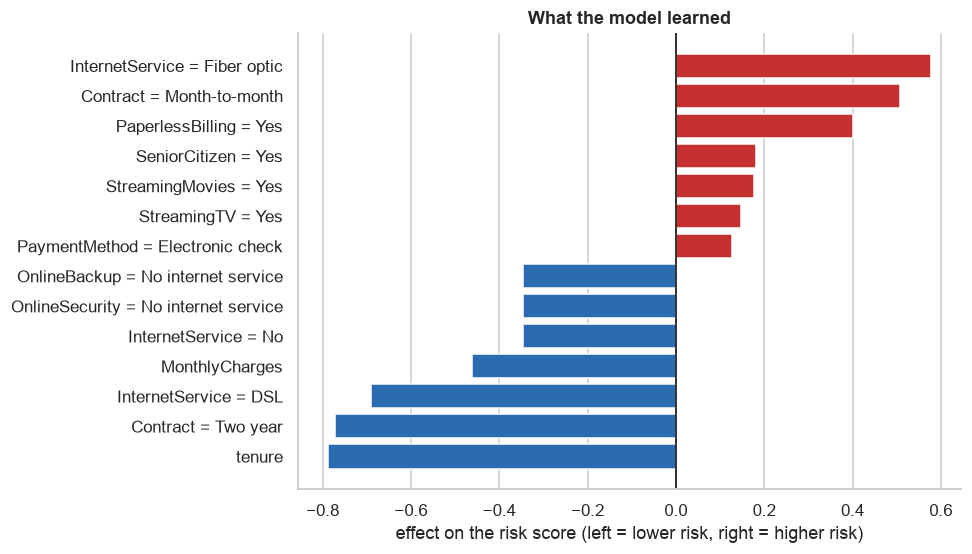

In [7]:
# Which factors push the risk score up (red) or down (blue)?
names = model[0].get_feature_names_out()
weights = pd.Series(model[-1].coef_[0], index=names)
readable = (weights.index.str.replace('num__', '', regex=False).str.replace('cat__', '', regex=False)
            .str.replace('_', ' = ', n=1, regex=False))
weights.index = readable
top = pd.concat([weights.nlargest(7), weights.nsmallest(7)]).sort_values()

fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh(top.index, top.values, color=[RED if v > 0 else BLUE for v in top.values])
ax.axvline(0, color='black', lw=1)
ax.set_xlabel('effect on the risk score (left = lower risk, right = higher risk)')
ax.set_title('What the model learned'); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.savefig('figures/05_model_factors.png', bbox_inches='tight'); plt.show()

**Insight:** the model is clearly better than guessing. If the company calls the **20% of customers with the highest risk scores**, it reaches **50% of everyone who would leave**, and 2 out of 3 people it calls really are about to leave. Random calls would reach only 20%, with about 1 in 4 really leaving. The simple rule (month-to-month and new customers first) does quite well too (44%), which confirms that contract and tenure are the most important factors. The model adds the other factors on top.

**What the model learned** matches the charts above: fiber internet, month-to-month contracts, paperless billing and being a senior citizen raise the risk, while a long tenure, a two-year contract and DSL internet lower it. The monthly bill shows a small negative effect, because once the model knows which services someone has, the bill adds little. The effect of price shows up mainly through the fiber service.

## 8. Q5: How many customers should get an offer, and how much would it save?

This turns the risk scores into money. The numbers below are **assumptions**, chosen to be realistic but simple. Change them to match the company's real figures:

- **Offer cost:** each customer who gets an offer costs **$60** (about one month's discount).
- **Success rate:** of the customers who were going to leave, **30%** stay because of the offer.
- **Value of keeping a customer:** a customer who stays pays their monthly bill for **12 more months**.

An offer sent to a customer who wasn't going to leave anyway is wasted money. That's why targeting matters: calling everyone costs a lot, while calling no one saves nothing.

The test customers are a 25% sample, so results are multiplied by 4 to show the whole customer base.

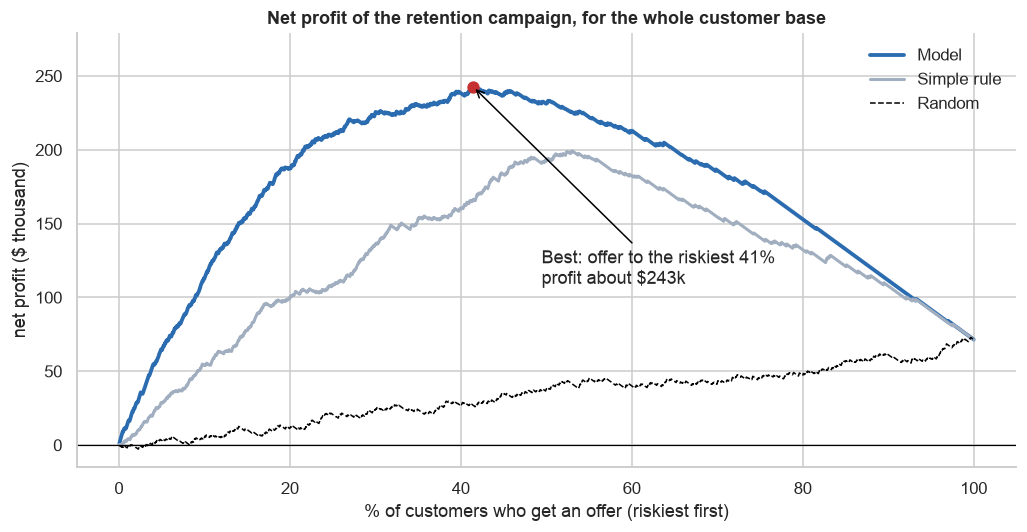

Best plan: 2,920 offers (41% of customers), reaching about 1,508 of the 1,869 leavers
Best profit with the simple rule instead of the model: $199,257


,Customers who get an offer,Net profit ($)
Plan,,
Offer to the riskiest customers (model),2920,"242,604.6"
Offer to everyone,7043,"71,491.6"
No offers,0,0.0


In [8]:
OFFER_COST = 60          # $ per customer who gets an offer
SUCCESS_RATE = 0.30      # share of would-be leavers who stay because of the offer
MONTHS_KEPT = 12         # months a saved customer keeps paying
SCALE = len(df) / len(test)

def profit_curve(score, success_rate=SUCCESS_RATE):
    order = test.sort_values(score, ascending=False)
    saved_value = (order['left'] * order['MonthlyCharges'] * MONTHS_KEPT * success_rate).cumsum().values
    cost = OFFER_COST * np.arange(1, len(order) + 1)
    return (saved_value - cost) * SCALE

profit_model, profit_rule = profit_curve('risk'), profit_curve('rule_score')
rng = np.random.default_rng(0)
test['random_score'] = rng.random(len(test))   # random order = no analysis at all
profit_random = profit_curve('random_score')

best = int(np.argmax(profit_model))
best_pct = pct_called[best]

fig, ax = plt.subplots(figsize=(9.5, 5))
ax.plot(pct_called, profit_model / 1000, color=BLUE, lw=2.5, label='Model')
ax.plot(pct_called, profit_rule / 1000, color=GREY, lw=2, label='Simple rule')
ax.plot(pct_called, profit_random / 1000, color='black', ls='--', lw=1, label='Random')
ax.axhline(0, color='black', lw=0.8)
ax.scatter([best_pct], [profit_model[best] / 1000], color=RED, zorder=3, s=50)
ax.annotate(f'Best: offer to the riskiest {best_pct:.0f}%\nprofit about ${profit_model[best] / 1000:,.0f}k',
            (best_pct, profit_model[best] / 1000), xytext=(best_pct + 8, profit_model[best] / 1000 * 0.45),
            arrowprops=dict(arrowstyle='->', color='black'))
ax.set_xlabel('% of customers who get an offer (riskiest first)'); ax.set_ylabel('net profit ($ thousand)')
ax.set_title('Net profit of the retention campaign, for the whole customer base')
ax.legend(frameon=False, loc='upper right')
ax.set_ylim(top=max(profit_model) / 1000 * 1.15)
plt.tight_layout(); plt.savefig('figures/06_profit.png', bbox_inches='tight'); plt.show()

offers = int(round((best + 1) * SCALE))
leavers_reached = test.nlargest(best + 1, 'risk')['left'].sum() * SCALE
campaign = pd.DataFrame({'Plan': ['Offer to the riskiest customers (model)', 'Offer to everyone', 'No offers'],
                         'Customers who get an offer': [offers, len(df), 0],
                         'Net profit ($)': [profit_model[best], profit_model[-1], 0]}).set_index('Plan')
print(f'Best plan: {offers:,} offers ({best_pct:.0f}% of customers), reaching about {leavers_reached:,.0f} of the {df["left"].sum():,} leavers')
print(f'Best profit with the simple rule instead of the model: ${profit_rule.max():,.0f}')
campaign

In [9]:
# What if the assumptions are wrong? Best result for different success rates
sensitivity = []
for rate in [0.15, 0.30, 0.45]:
    curve = profit_curve('risk', success_rate=rate)
    i = int(np.argmax(curve))
    sensitivity.append({'Success rate': f'{rate:.0%}', 'Best % of customers to target': pct_called[i],
                        'Net profit ($)': curve[i], 'Profit if offered to everyone ($)': curve[-1]})
sensitivity = pd.DataFrame(sensitivity).set_index('Success rate')
sensitivity

,Best % of customers to target,Net profit ($),Profit if offered to everyone ($)
Success rate,,,
15%,21.8,"55,040.9","-175,544.2"
30%,41.5,"242,604.6","71,491.6"
45%,45.8,"456,366.8","318,527.4"


**Insight:** targeting is what makes the campaign pay off.
- **Best plan:** give the offer to the **riskiest 41% of customers** (about 2,900 people). This reaches about 1,500 of the 1,869 leavers and earns about **$243,000 net profit**.
- **Offering it to everyone** earns only $71,000, because most of the money goes to customers who were never going to leave.
- **The model beats the simple rule** at every campaign size (best profit about $243,000 against about $200,000).
- **If the offer works only half as well** (a 15% success rate), targeting still makes about $55,000, while offering it to everyone would **lose $176,000**. Good targeting protects the company when the offer works worse than hoped.

## 9. Results to copy into the summary

In [10]:
summary = {
    'Customers': f'{len(df):,}',
    'Left in the last month': f"{df['left'].sum():,} ({df['left'].mean():.1%})",
    'Revenue lost per year': f'${12 * lost_revenue:,.0f}',
    'Highest-churn group': f"{groups.iloc[0]['group']} ({groups.iloc[0]['pct_left']:.0f}% left)",
    'Riskiest combination': f"{ladder.iloc[-1]['pct_left']:.0f}% left ({ladder.iloc[-1]['customers']:,} customers)",
    'Model AUC': f"{roc_auc_score(test['left'], test['risk']):.2f}",
    'Call top 20%, reach': f'{found_model[k]:.0f}% of leavers',
    'Best campaign size': f'{best_pct:.0f}% of customers ({offers:,} offers)',
    'Best net profit': f'${profit_model[best]:,.0f}',
}
for key, value in summary.items():
    print(f'{key:<26} {value}')

groups.to_csv('outputs/churn_by_group.csv', index=False)
ladder.to_csv('outputs/risk_ladder.csv', index=False)
reach.to_csv('outputs/model_reach.csv')
sensitivity.to_csv('outputs/profit_sensitivity.csv')
test[['customerID', 'risk']].sort_values('risk', ascending=False).to_csv('outputs/test_customers_risk_scores.csv', index=False)

Customers                  7,043
Left in the last month     1,869 (26.5%)
Revenue lost per year      $1,669,570
Highest-churn group        tenure_group = 0-6 months (53% left)
Riskiest combination       71% left (631 customers)
Model AUC                  0.84
Call top 20%, reach        50% of leavers
Best campaign size         41% of customers (2,920 offers)
Best net profit            $242,605


## 10. Recommendations

| # | Recommendation | Why |
|---|---|---|
| 1 | **Run a targeted retention campaign** for the riskiest 40% of customers, using the model's risk scores | It earns about $243,000 a year, more than 3 times as much as offering it to everyone, and stays profitable even if the offer works half as well as assumed |
| 2 | **Focus on the first year:** a welcome programme, check-in calls and onboarding help for new customers | 53% of customers leave in their first 6 months, and only 10% after 4 years |
| 3 | **Encourage longer contracts**, for example with a discount for switching from month-to-month to a 1- or 2-year plan | 43% of month-to-month customers leave, against 3% on two-year contracts |
| 4 | **Investigate the fiber optic service** (price, speed, outages) | Fiber customers leave twice as often as DSL customers, and they are the most valuable |
| 5 | **Promote automatic payments and tech support**, for example by bundling tech support into fiber plans | Customers with automatic payments or tech support leave much less often |
| 6 | **Test the offer first** on a small random group before rolling it out | The success rate is the biggest uncertainty in the profit estimate |

## 11. Limitations

- **Sample data:** this is IBM's fictional sample dataset, so the numbers show the method, not a real company's results.
- **One snapshot:** the data shows who left in one month. It can't show how risk changes over time or why each customer left.
- **Assumed offer results:** the $60 cost, 30% success rate and 12 months are assumptions. A real company should test the offer on a small group first (an A/B test) to measure the real success rate.
- **Correlation, not cause:** month-to-month customers leave more often, but moving someone to a yearly contract won't necessarily make them stay. They may have chosen month-to-month because they were already unsure.
- **Simple model:** a more complex model (such as gradient boosting) might predict slightly better, but logistic regression is easy to explain, which matters when the business needs to trust it.